In [2]:
import pandas as pd

df = pd.read_excel("sensor_data.xlsx")
print(df.head())
print(df.shape)

                     time  pressure
0 2026-01-01 01:00:00.000      12.0
1 2026-01-02 02:30:00.000      20.0
2 2026-01-03 03:00:00.000      20.5
3 2026-01-04 04:30:00.000      30.0
4 2026-01-05 00:59:59.995      30.5
(5, 2)


                                time   pressure
count                              5   5.000000
mean   2026-01-03 02:23:59.999000064  22.600000
min              2026-01-01 01:00:00  12.000000
25%              2026-01-02 02:30:00  20.000000
50%              2026-01-03 03:00:00  20.500000
75%              2026-01-04 04:30:00  30.000000
max       2026-01-05 00:59:59.995000  30.500000
std                              NaN   7.757255


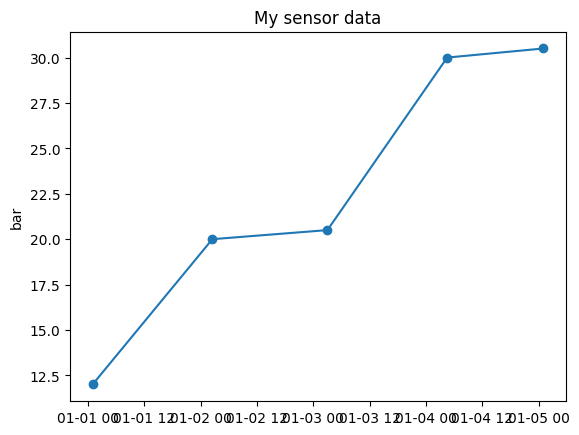

In [3]:
print(df.describe())

import matplotlib.pyplot as plt
plt.plot(df["time"], df["pressure"], marker="o")
plt.title("My sensor data")
plt.ylabel("bar")
plt.show()


                                time   pressure
count                              5   5.000000
mean   2026-01-03 02:23:59.999000064  22.600000
min              2026-01-01 01:00:00  12.000000
25%              2026-01-02 02:30:00  20.000000
50%              2026-01-03 03:00:00  20.500000
75%              2026-01-04 04:30:00  30.000000
max       2026-01-05 00:59:59.995000  30.500000
std                              NaN   7.757255


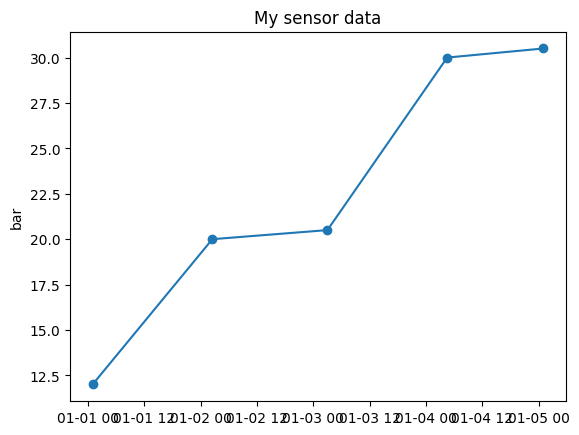

In [4]:
print(df.describe())

import matplotlib.pyplot as plt
plt.plot(df["time"], df["pressure"], marker="o")
plt.title("My sensor data")
plt.ylabel("bar")
plt.show()

In [5]:
print(df)
print(df["pressure"].max())

                     time  pressure
0 2026-01-01 01:00:00.000      12.0
1 2026-01-02 02:30:00.000      20.0
2 2026-01-03 03:00:00.000      20.5
3 2026-01-04 04:30:00.000      30.0
4 2026-01-05 00:59:59.995      30.5
30.5


In [6]:
import pandas as pd

df = pd.read_excel("sensor_data.xlsx")
print(df)
print("Max pressure:", df["pressure"].max())

                      time  pressure
0  2026-01-01 23:00:00.000      12.0
1  2026-01-02 22:30:00.000      20.0
2  2026-01-03 21:00:00.000      20.5
3  2026-01-04 20:30:00.000      30.0
4  2026-01-05 19:00:00.000      30.5
5  2026-01-06 18:00:00.000      40.0
6  2026-01-07 17:00:00.000      30.0
7  2026-01-08 16:00:00.000      33.0
8  2026-01-09 15:00:00.000      80.0
9  2026-01-10 14:00:00.000      33.0
10 2026-01-11 13:00:00.000      40.0
11 2026-01-12 12:00:00.000      50.0
12 2026-01-13 11:00:00.000      20.0
13 2026-01-14 10:00:00.000     100.0
14 2026-01-15 09:00:00.000      20.0
15 2026-01-16 08:00:00.000      22.0
16 2026-01-17 07:00:00.000      30.0
17 2026-01-18 05:00:00.000      33.0
18 2026-01-19 04:00:00.000      20.0
19 2026-01-20 03:00:00.000      22.0
20 2026-01-21 02:00:00.000      25.0
21 2026-01-22 00:59:59.995      25.0
22 2026-01-23 00:00:00.000      24.0
23 2026-01-24 23:40:00.000      30.0
24 2026-01-25 23:00:00.000      90.0
25 2026-01-26 22:00:00.000      22.0
2

Limits: 9.6 to 42.6
Anomalies: 4
                  time  pressure  anomaly
8  2026-01-09 15:00:00      80.0     True
11 2026-01-12 12:00:00      50.0     True
13 2026-01-14 10:00:00     100.0     True
24 2026-01-25 23:00:00      90.0     True


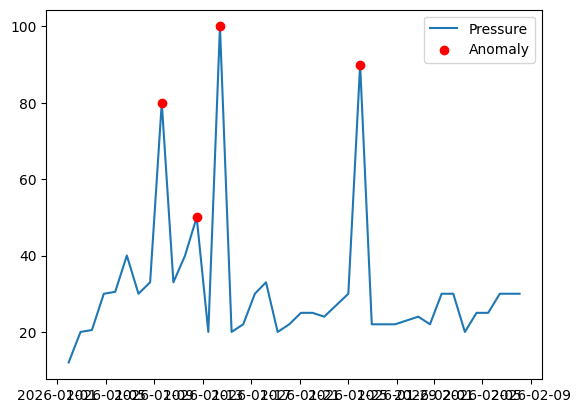

In [7]:
q1 = df["pressure"].quantile(0.25)
q3 = df["pressure"].quantile(0.75)
iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

df["anomaly"] = (df["pressure"] < low) | (df["pressure"] > high)

print("Limits:", round(low, 1), "to", round(high, 1))
print("Anomalies:", df["anomaly"].sum())
print(df[df["anomaly"]])

import matplotlib.pyplot as plt
plt.plot(df["time"], df["pressure"], label="Pressure")
plt.scatter(df[df["anomaly"]]["time"], df[df["anomaly"]]["pressure"],
            color="red", label="Anomaly", zorder=3)
plt.legend()
plt.show()

pressure anomalies: 4
temperature anomalies: 3
flow anomalies: 1


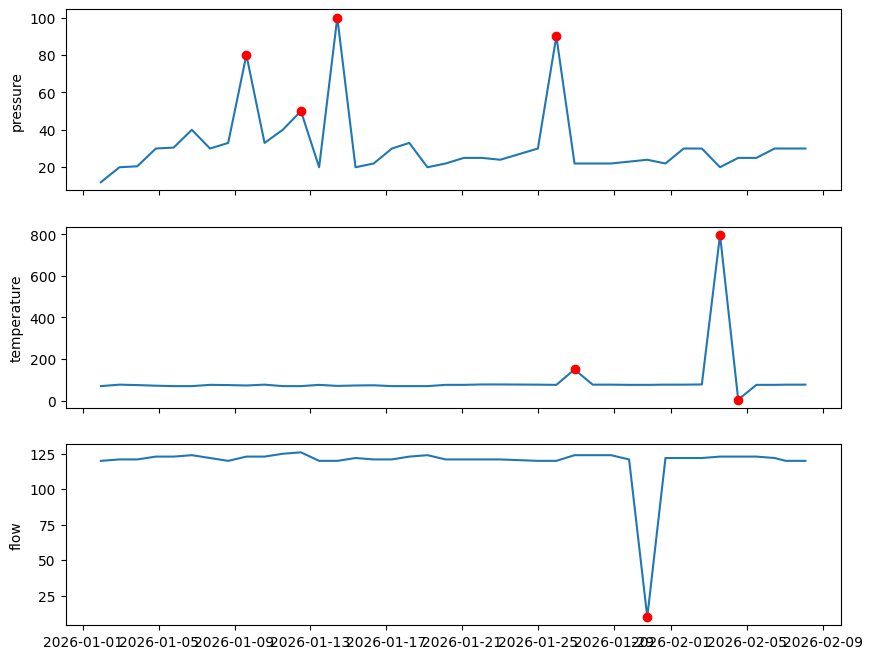

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("sensor_data.xlsx")

def find_anomalies(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    return (series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)

sensors = ["pressure", "temperature", "flow"]

for col in sensors:
    df[col + "_anomaly"] = find_anomalies(df[col])
    print(col, "anomalies:", df[col + "_anomaly"].sum())

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
for ax, col in zip(axes, sensors):
    ax.plot(df["time"], df[col])
    bad = df[df[col + "_anomaly"]]
    ax.scatter(bad["time"], bad[col], color="red", zorder=3)
    ax.set_ylabel(col)
plt.show()

In [15]:
for col in ["pressure", "temperature", "flow"]:
    print("---", col)
    print(df[df[col + "_anomaly"]][["time", col]])

--- pressure
                  time  pressure
8  2026-01-09 15:00:00      80.0
11 2026-01-12 12:00:00      50.0
13 2026-01-14 10:00:00     100.0
24 2026-01-25 23:00:00      90.0
--- temperature
                  time  temperature
25 2026-01-26 22:00:00          150
33 2026-02-03 14:00:00          797
34 2026-02-04 13:00:00            5
--- flow
                  time  flow
29 2026-01-30 18:00:00    10
